# Thai Fake News Detection — 3 พารามิเตอร์ × 5 ค่า (ตามที่อาจารย์สั่ง)

**ขั้นตอน (เลือกค่าที่ดีที่สุดด้วย *validation loss ต่ำสุด* ไม่ใช่ดูจาก F1 หรือเลือก epoch สุดท้าย)**

| ตาราง | พารามิเตอร์ที่เปลี่ยน (5 ค่า) | ค่าที่ fix ไว้ | เลือกค่าที่ดีที่สุดจาก |
|---|---|---|---|
| 1 | #1 epochs = 10, 20, 30, 40, 50 | seed = 42, learning rate (หรือ alpha ของ SVM) = ค่า default | val loss ต่ำสุด |
| 2 | #2 random seed = 5 ค่า | epochs = ค่าที่ดีที่สุดจากตาราง 1 | val loss ต่ำสุด |
| 3 | #3 learning rate = 5 ค่า (SVM ใช้ alpha) | epochs + seed ที่ดีที่สุดจากตาราง 1, 2 | val loss ต่ำสุด |
| สุดท้าย | — | #1, #2, #3 ที่ดีที่สุดของแต่ละโมเดล | รัน **test set** ครั้งเดียว → P / R / F1 |

> หมายเหตุ: พารามิเตอร์ #3 ในโน้ตเขียนไว้แค่ว่า "พารามิเตอร์" ตอนนี้ตั้งเป็น learning rate (ของ SVM คือ `alpha`) ถ้าอาจารย์หมายถึงตัวอื่น (เช่น batch size) แก้ที่ `LR_GRID` ในเซลล์ config ได้

> ผลทุกขั้นถูกเก็บในโฟลเดอร์ `results/` (cache) ถ้า Colab หลุดแล้วรันซ้ำจะไม่ต้องเทรนใหม่ ถ้าเปลี่ยน config ให้ลบโฟลเดอร์ `results/` ก่อน

In [6]:
!pip -q install pythainlp peft datasets accelerate evaluate
!pip -q install -U transformers
# torchao เวอร์ชันเก่าที่ติดมากับ Colab ทำให้ peft import ไม่ผ่าน -> ถอนออก (ไม่ได้ใช้)
!pip -q uninstall -y torchao

## 0) Config และฟังก์ชันช่วย

In [7]:
import os, gc, random, pickle, warnings
import numpy as np, pandas as pd, torch
import matplotlib.pyplot as plt
from transformers import set_seed
from sklearn.model_selection import train_test_split
from sklearn.metrics import precision_recall_fscore_support, hinge_loss
from sklearn.exceptions import ConvergenceWarning
warnings.filterwarnings("ignore", category=ConvergenceWarning)

SEED = 42
AVERAGE = "binary"          # "binary" = ข่าวปลอมเป็น positive class | "macro" = เฉลี่ยสองคลาส
OUT = "results"; os.makedirs(OUT, exist_ok=True)

MODELS = ["TF-IDF+SVM", "Thai-BERT", "Typhoon-1B-LoRA"]

# พารามิเตอร์ #1 : epochs
EPOCHS_LIST = [10, 20, 30, 40, 50]
MAX_EPOCH = max(EPOCHS_LIST)

# พารามิเตอร์ #2 : random seed (5 ค่า)
SEEDS = [42, 7, 123, 2024, 99]

# พารามิเตอร์ #3 : learning rate (SVM = alpha, ยิ่งมากยิ่ง regularize แรง)
DEFAULT_LR = {"TF-IDF+SVM": 1e-4, "Thai-BERT": 2e-5, "Typhoon-1B-LoRA": 2e-4}
LR_GRID = {
    "TF-IDF+SVM":      [1e-6, 1e-5, 1e-4, 1e-3, 1e-2],
    "Thai-BERT":       [1e-5, 2e-5, 3e-5, 5e-5, 1e-4],
    "Typhoon-1B-LoRA": [5e-5, 1e-4, 2e-4, 3e-4, 5e-4],
}

# "grid" = เลือก epoch จาก 10,20,30,40,50 | "all" = เลือกจุด val loss ต่ำสุดจากทุก epoch (1..50)
PICK_FROM = "grid"

def seed_all(s=SEED):
    random.seed(s); np.random.seed(s); torch.manual_seed(s)
    torch.cuda.manual_seed_all(s); set_seed(s)
seed_all()

def prf(y_true, y_pred):
    p, r, f, _ = precision_recall_fscore_support(y_true, y_pred, average=AVERAGE, zero_division=0)
    return p, r, f

def cached(path, fn):
    # รันครั้งแรกแล้วเก็บผล, ครั้งต่อไปโหลดจากไฟล์
    if os.path.exists(path):
        with open(path, "rb") as f:
            return pickle.load(f)
    obj = fn()
    with open(path, "wb") as f:
        pickle.dump(obj, f)
    return obj

## 1) Dataset: ดึงมาจากไหน / จำนวนเท่าไหร่
อาจารย์ให้ระบุที่มาของ dataset ใน paper เซลล์นี้พิมพ์ข้อมูลที่ต้องใช้เขียน (ชื่อ dataset, จำนวนแถวดิบ, จำนวนหลังทำความสะอาด, จำนวนต่อคลาสในแต่ละ split)

In [8]:
from datasets import load_dataset

DATASET_ID = "EXt1/Thai-True-Fake-News"      # Hugging Face: https://huggingface.co/datasets/EXt1/Thai-True-Fake-News
raw = load_dataset(DATASET_ID)
print(raw)
df0 = raw["train"].to_pandas()
print("columns:", df0.columns.tolist())
print("แถวดิบ:", len(df0))
print(df0["Verification_Status"].value_counts())
display(df0.head(3))

df = df0[["Title", "Verification_Status"]].dropna().drop_duplicates(subset="Title")
df["label"] = (df["Verification_Status"] == "ข่าวปลอม").astype(int)   # 1 = ข่าวปลอม
df = df.reset_index(drop=True)
print(f"ใช้จริง {len(df)} แถว (ตัด null/ชื่อข่าวซ้ำออก {len(df0) - len(df)} แถว)")

train_df, tmp_df = train_test_split(df, test_size=0.2, stratify=df["label"], random_state=SEED)
val_df, test_df = train_test_split(tmp_df, test_size=0.5, stratify=tmp_df["label"], random_state=SEED)

split_summary = pd.DataFrame(
    {n: d["label"].value_counts().rename({0: "ข่าวจริง", 1: "ข่าวปลอม"}) for n, d in
     [("train", train_df), ("val", val_df), ("test", test_df)]}).T
split_summary["total"] = split_summary.sum(axis=1)
display(split_summary)
split_summary.to_csv(f"{OUT}/dataset_split_summary.csv")

README.md:   0%|          | 0.00/747 [00:00<?, ?B/s]

dataset.csv:   0%|          | 0.00/1.44M [00:00<?, ?B/s]

Generating train split:   0%|          | 0/6004 [00:00<?, ? examples/s]

DatasetDict({
    train: Dataset({
        features: ['Unnamed: 0', 'Title', 'Verification_Status'],
        num_rows: 6004
    })
})
columns: ['Unnamed: 0', 'Title', 'Verification_Status']
แถวดิบ: 6004
Verification_Status
ข่าวปลอม    3002
ข่าวจริง    3002
Name: count, dtype: int64


,Unnamed: 0,Title,Verification_Status
0,3413.0,กรมพัฒนาธุรกิจการค้าอนุญาตใบทะเบียนพาณิชย์ราย...,ข่าวปลอม
1,7926.0,กรมการจัดหางานส่งเสริมให้ชาวไทยมีรายได้ เฉลี่...,ข่าวปลอม
2,3285.0,ตลาดหลักทรัพย์แห่งประเทศไทยเปิดลงทุนเพื่อหาค่...,ข่าวปลอม


ใช้จริง 5749 แถว (ตัด null/ชื่อข่าวซ้ำออก 255 แถว)


label,ข่าวจริง,ข่าวปลอม,total
train,2395,2204,4599
val,299,276,575
test,300,275,575


## 2) TF-IDF + SVM (loss = hinge loss เฉลี่ย ไม่รวม regularization)

In [9]:
from pythainlp.tokenize import word_tokenize
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.linear_model import SGDClassifier

tok_th = lambda t: word_tokenize(t, engine="newmm", keep_whitespace=False)
tfidf = TfidfVectorizer(tokenizer=tok_th, token_pattern=None,
                        ngram_range=(1, 2), min_df=2, sublinear_tf=True)
Xtr = tfidf.fit_transform(train_df["Title"])
Xva = tfidf.transform(val_df["Title"])
Xte = tfidf.transform(test_df["Title"])
ytr, yva, yte = train_df["label"].values, val_df["label"].values, test_df["label"].values

def _run_svm(epochs, seed, alpha, test=False):
    # SGDClassifier(max_iter=e, tol=None) = เทรนครบ e epochs พอดี -> fit ใหม่ทุก e เพื่อได้เส้นโค้ง epoch 1..epochs
    rows, vpreds, clf = [], [], None
    for e in range(1, epochs + 1):
        clf = SGDClassifier(loss="hinge", alpha=alpha, max_iter=e, tol=None, random_state=seed)
        clf.fit(Xtr, ytr)
        d_tr, d_va = clf.decision_function(Xtr), clf.decision_function(Xva)
        pred = (d_va > 0).astype(int)
        p, r, f = prf(yva, pred)
        rows.append(dict(epoch=e,
                         train_loss=hinge_loss(ytr, d_tr, labels=[0, 1]),
                         val_loss=hinge_loss(yva, d_va, labels=[0, 1]),
                         P=p, R=r, F1=f))
        vpreds.append(pred)
    res = dict(hist=pd.DataFrame(rows), val_preds=np.array(vpreds), test=None)
    if test:
        d_te = clf.decision_function(Xte)
        p, r, f = prf(yte, (d_te > 0).astype(int))
        res["test"] = dict(test_loss=hinge_loss(yte, d_te, labels=[0, 1]), P=p, R=r, F1=f)
    return res

## 3) Thai-BERT และ Typhoon-1B-LoRA (loss = cross-entropy)
- `train_loss` = ค่าเฉลี่ย training loss ของ epoch นั้น (ได้จาก Trainer log) และ `val_loss` = loss บน validation set หลังจบ epoch นั้น
- เก็บค่าทุก epoch (1..epochs) เพื่อเอาไปพล็อตกราฟ

In [10]:
from datasets import Dataset
from transformers import (AutoTokenizer, AutoModelForSequenceClassification,
                          TrainingArguments, Trainer, DataCollatorWithPadding)

HF_CFG = {
    "Thai-BERT":       ("airesearch/wangchanberta-base-att-spm-uncased", dict(batch_size=32, lora=False)),
    "Typhoon-1B-LoRA": ("scb10x/llama3.2-typhoon2-1b-instruct",          dict(batch_size=16, lora=True)),
}

_DATA = {}
def get_data(name, max_len=64):
    if name in _DATA:
        return _DATA[name]
    tok = AutoTokenizer.from_pretrained(name)
    if tok.pad_token is None:
        tok.pad_token = tok.eos_token
    def enc(d):
        ds = Dataset.from_pandas(d[["Title", "label"]].reset_index(drop=True))
        ds = ds.map(lambda b: tok(b["Title"], truncation=True, max_length=max_len), batched=True)
        return ds.remove_columns(["Title"]).rename_column("label", "labels")
    _DATA[name] = (tok, enc(train_df), enc(val_df), enc(test_df))
    return _DATA[name]

def _run_hf(model, epochs, seed, lr, test=False):
    name, cfg = HF_CFG[model]
    seed_all(seed)
    tok, tr_ds, va_ds, te_ds = get_data(name)
    net = AutoModelForSequenceClassification.from_pretrained(name, num_labels=2, dtype=torch.float32)
    net.config.pad_token_id = tok.pad_token_id
    if cfg["lora"]:
        from peft import LoraConfig, get_peft_model
        lcfg = LoraConfig(r=16, lora_alpha=32, lora_dropout=0.05, task_type="SEQ_CLS",
                          target_modules=["q_proj", "k_proj", "v_proj", "o_proj"])
        net = get_peft_model(net, lcfg)

    vpreds = []
    def metrics(ep):
        logits, labels = ep
        pred = np.argmax(logits, axis=-1)
        vpreds.append(pred)
        p, r, f = prf(labels, pred)
        return {"P": p, "R": r, "F1": f}

    steps_per_epoch = -(-len(tr_ds) // cfg["batch_size"])
    args = TrainingArguments(
        output_dir=f"/content/out_{model}", num_train_epochs=epochs,
        per_device_train_batch_size=cfg["batch_size"], per_device_eval_batch_size=64,
        learning_rate=lr, weight_decay=0.01, warmup_steps=int(0.05 * steps_per_epoch * epochs),
        eval_strategy="epoch", logging_strategy="epoch", save_strategy="no",
        fp16=torch.cuda.is_available(), seed=seed, data_seed=seed, report_to="none")
    trainer = Trainer(model=net, args=args, train_dataset=tr_ds, eval_dataset=va_ds,
                      data_collator=DataCollatorWithPadding(tok), compute_metrics=metrics)
    trainer.train()

    log = trainer.state.log_history
    tr_loss = {int(round(l["epoch"])): l["loss"] for l in log if "loss" in l and "eval_loss" not in l}
    rows = []
    for l in log:
        if "eval_loss" in l:
            ep = int(round(l["epoch"]))
            rows.append(dict(epoch=ep, train_loss=tr_loss.get(ep, np.nan), val_loss=l["eval_loss"],
                             P=l["eval_P"], R=l["eval_R"], F1=l["eval_F1"]))
    res = dict(hist=pd.DataFrame(rows), val_preds=np.array(vpreds[:epochs]), test=None)
    if test:
        m = trainer.evaluate(te_ds, metric_key_prefix="test")
        res["test"] = dict(test_loss=m["test_loss"], P=m["test_P"], R=m["test_R"], F1=m["test_F1"])

    del net, trainer
    gc.collect(); torch.cuda.empty_cache()
    return res

def _run(model, epochs, seed, lr, test=False):
    if model == "TF-IDF+SVM":
        return _run_svm(epochs, seed, lr, test)
    return _run_hf(model, epochs, seed, lr, test)

## 4) ตาราง 1 — เปลี่ยน epochs (10–50) ให้ seed และ learning rate เป็นค่า default
เทรนครั้งเดียวถึง 50 epochs แล้วอ่านค่าที่ epoch 10, 20, 30, 40, 50 (และเก็บทุก epoch ไว้พล็อต) โมเดลที่ดีที่สุด = epoch ที่ **val loss ต่ำสุด**

In [11]:
S1 = {}
for m in MODELS:
    S1[m] = cached(f"{OUT}/stage1_{m}.pkl", lambda m=m: _run(m, MAX_EPOCH, SEED, DEFAULT_LR[m]))

H1 = pd.concat([S1[m]["hist"].assign(model=m) for m in MODELS], ignore_index=True)
COLS = ["model", "epoch", "train_loss", "val_loss", "P", "R", "F1"]
T1 = H1[H1["epoch"].isin(EPOCHS_LIST)][COLS].reset_index(drop=True)

def pick_best_epoch(h):
    d = h[h["epoch"].isin(EPOCHS_LIST)] if PICK_FROM == "grid" else h
    return int(d.loc[d["val_loss"].idxmin(), "epoch"])      # เสมอกัน -> เลือก epoch น้อยกว่า

BEST_EPOCH = {m: pick_best_epoch(S1[m]["hist"]) for m in MODELS}
T1["best"] = T1.apply(lambda r: "<-- best" if r["epoch"] == BEST_EPOCH[r["model"]] else "", axis=1)
display(T1.round(4))
print("epoch ที่ดีที่สุด (val loss ต่ำสุด):", BEST_EPOCH)
T1.round(4).to_csv(f"{OUT}/table1_epochs.csv", index=False)
H1.round(6).to_csv(f"{OUT}/stage1_all_epochs.csv", index=False)

config.json:   0%|          | 0.00/546 [00:00<?, ?B/s]

tokenizer_config.json:   0%|          | 0.00/282 [00:00<?, ?B/s]

sentencepiece.bpe.model:   0%|          | 0.00/905k [00:00<?, ?B/s]

Map:   0%|          | 0/4599 [00:00<?, ? examples/s]

Map:   0%|          | 0/575 [00:00<?, ? examples/s]

Map:   0%|          | 0/575 [00:00<?, ? examples/s]

... (16 outputs left out)

[transformers] LlamaForSequenceClassification LOAD REPORT from: scb10x/llama3.2-typhoon2-1b-instruct
Key          | Status  | 
-------------+---------+-
score.weight | MISSING | 

Notes:
- MISSING:	those params were newly initialized because missing from the checkpoint. Consider training on your downstream task.


Epoch,Training Loss,Validation Loss,P,R,F1
1,0.321037,0.044246,0.992806,1.000000,0.996390
2,0.032601,0.058412,0.992754,0.992754,0.992754
3,0.017049,0.018891,0.996390,1.000000,0.998192
4,0.026222,0.027779,0.996377,0.996377,0.996377
5,0.009459,0.041100,0.996377,0.996377,0.996377
6,0.001378,0.041261,0.996364,0.992754,0.994555
7,0.000396,0.048049,0.996364,0.992754,0.994555
8,0.000013,0.044412,0.992754,0.992754,0.992754
9,0.000015,0.050975,0.996364,0.992754,0.994555
10,0.000000,0.050952,0.996364,0.992754,0.994555


,model,epoch,train_loss,val_loss,P,R,F1,best
0,TF-IDF+SVM,10,0.0374,0.2857,0.8993,0.9058,0.9025,<-- best
1,TF-IDF+SVM,20,0.0328,0.2885,0.9158,0.9058,0.9107,
2,TF-IDF+SVM,30,0.0308,0.2918,0.9091,0.9058,0.9074,
3,TF-IDF+SVM,40,0.0304,0.2937,0.9191,0.9058,0.9124,
4,TF-IDF+SVM,50,0.0298,0.2943,0.9191,0.9058,0.9124,
5,Thai-BERT,10,0.0862,0.3372,0.8789,0.9203,0.8991,<-- best
6,Thai-BERT,20,0.0103,0.5474,0.8942,0.9493,0.9209,
7,Thai-BERT,30,0.0068,0.6504,0.8792,0.9493,0.9129,
8,Thai-BERT,40,0.0050,0.6157,0.8935,0.9420,0.9171,
9,Thai-BERT,50,0.0032,0.6352,0.8951,0.9275,0.9110,


epoch ที่ดีที่สุด (val loss ต่ำสุด): {'TF-IDF+SVM': 10, 'Thai-BERT': 10, 'Typhoon-1B-LoRA': 10}


### กราฟ training loss และ validation loss แยกกัน (คนละรูป) ทุก epoch — ใส่ภาคผนวก ไม่ต้องใส่ใน paper

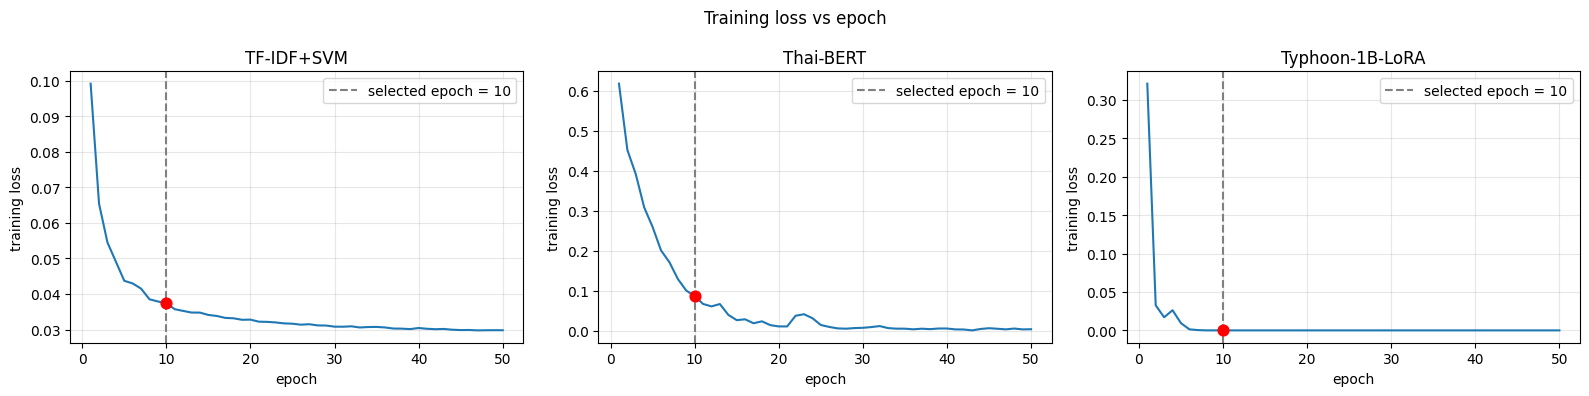

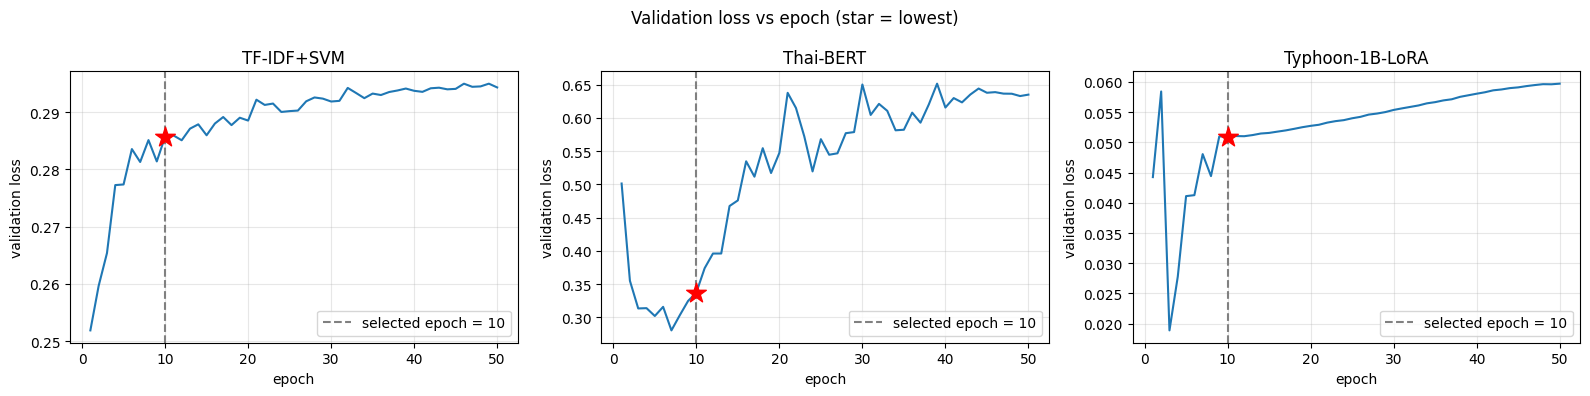

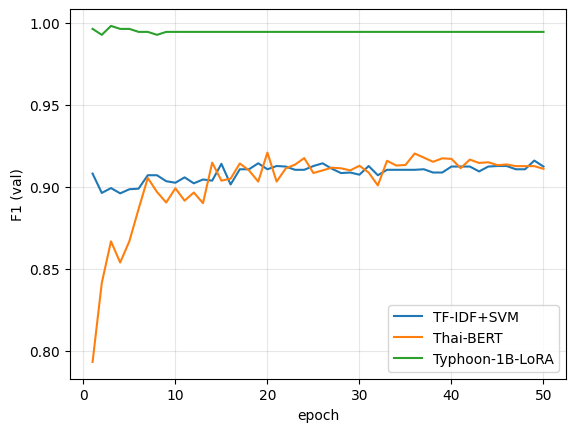

In [12]:
def plot_epoch_curves(col, ylabel, title, fname, star=False):
    # 1 รูป = 1 ชนิด loss, แยก subplot ตามโมเดล (เส้นประ = epoch ที่เลือกจาก val loss ต่ำสุด)
    fig, axes = plt.subplots(1, 3, figsize=(16, 4))
    for ax, m in zip(axes, MODELS):
        h = S1[m]["hist"]; b = BEST_EPOCH[m]
        ax.plot(h["epoch"], h[col])
        ax.axvline(b, ls="--", c="gray", label=f"selected epoch = {b}")
        ax.scatter([b], [h.loc[h["epoch"] == b, col].iloc[0]], marker="*" if star else "o",
                   s=220 if star else 60, c="red", zorder=5)
        ax.set_title(m); ax.set_xlabel("epoch"); ax.set_ylabel(ylabel); ax.grid(alpha=.3); ax.legend()
    fig.suptitle(title); plt.tight_layout()
    plt.savefig(f"{OUT}/{fname}", dpi=150, bbox_inches="tight"); plt.show()

# กราฟที่ 1: training loss อย่างเดียว
plot_epoch_curves("train_loss", "training loss", "Training loss vs epoch", "fig_train_loss_vs_epoch.png")
# กราฟที่ 2: validation loss อย่างเดียว (ดาวแดง = จุด val loss ต่ำสุดที่เลือก)
plot_epoch_curves("val_loss", "validation loss", "Validation loss vs epoch (star = lowest)",
                  "fig_val_loss_vs_epoch.png", star=True)

# F1 บน validation ทุก epoch (เอาไว้เทียบ ไม่ใช้เลือกค่าที่ดีที่สุด)
for m in MODELS:
    h = S1[m]["hist"]; plt.plot(h["epoch"], h["F1"], label=m)
plt.xlabel("epoch"); plt.ylabel("F1 (val)"); plt.grid(alpha=.3); plt.legend()
plt.savefig(f"{OUT}/fig_f1_vs_epoch.png", dpi=150, bbox_inches="tight"); plt.show()

## 5) ตรวจว่าทำไม Typhoon ได้ค่าเท่ากันทุก epoch (อาจารย์ให้เทสต์)
เซลล์นี้เช็ก 4 อย่างที่เป็นสาเหตุที่เป็นไปได้:
1. **จำนวนข้อที่ทายผิดบน val ในแต่ละ epoch** และ **prediction เปลี่ยนไปกี่ข้อระหว่าง epoch** ถ้าผิดจำนวนเดิมและ prediction ไม่เปลี่ยน = โมเดลหยุดเรียนรู้/จำ train set จนครบแล้ว F1 จึงนิ่ง
2. **ข้อที่ผิดซ้ำทุก epoch** คือข้อไหน (อาจเป็น label noise)
3. **near-duplicate ระหว่าง val/test กับ train** (cosine similarity ของ TF-IDF) ถ้ามีมาก = data leakage ทำให้คะแนนสูงเกินจริง
4. **คำที่ SVM ให้น้ำหนักสูงสุด** ถ้าเป็นคำอย่าง "ข่าวปลอม", "อย่าแชร์" = โมเดลอาศัยคำชี้นำ (shortcut) แทนเนื้อหา

In [13]:
idx = [e - 1 for e in EPOCHS_LIST]
print("== 1) จำนวนข้อที่ทายผิดบน val (epoch 10,20,30,40,50) / จำนวน prediction ที่เปลี่ยนจาก epoch ก่อนหน้า ==")
for m in MODELS:
    P = S1[m]["val_preds"]
    err = (P != yva).sum(axis=1)
    chg = np.r_[0, (P[1:] != P[:-1]).sum(axis=1)]
    print(f"{m:16s} errors={err[idx].tolist()}  changed={chg[idx].tolist()}  | epoch ที่ prediction เปลี่ยนล่าสุด = {int(np.nonzero(chg)[0].max() + 1) if chg.any() else 'ไม่เปลี่ยนเลย'}")

print("\n== 2) ข้อที่ Typhoon ทายผิดซ้ำทุก epoch ==")
P = S1["Typhoon-1B-LoRA"]["val_preds"]
wrong = np.where((P[idx] != yva).all(axis=0))[0]
display(val_df.iloc[wrong][["Title", "label"]])

print("== 3) near-duplicate กับ train (cosine similarity สูงสุดต่อ 1 ข่าว) ==")
for nm, X in [("val", Xva), ("test", Xte)]:
    sim = (X @ Xtr.T).max(axis=1).toarray().ravel()
    print(f"{nm}: sim>=0.9 = {(sim >= 0.9).mean():.1%} | sim>=0.8 = {(sim >= 0.8).mean():.1%}")

print("\n== 4) คำที่ SVM ให้น้ำหนักสูงสุด ==")
svm_ = SGDClassifier(loss="hinge", alpha=DEFAULT_LR["TF-IDF+SVM"], max_iter=MAX_EPOCH, tol=None, random_state=SEED).fit(Xtr, ytr)
vocab, w = np.array(tfidf.get_feature_names_out()), svm_.coef_[0]
print("ชี้ไปทาง 'ข่าวปลอม':", vocab[np.argsort(-w)[:15]].tolist())
print("ชี้ไปทาง 'ข่าวจริง':", vocab[np.argsort(w)[:15]].tolist())

print("\n== train loss ของ Typhoon (ถ้าเข้าใกล้ 0 แต่เนิ่น ๆ = จำ train set ได้แล้ว) ==")
display(S1["Typhoon-1B-LoRA"]["hist"][["epoch", "train_loss", "val_loss"]].iloc[idx].round(5))

== 1) จำนวนข้อที่ทายผิดบน val (epoch 10,20,30,40,50) / จำนวน prediction ที่เปลี่ยนจาก epoch ก่อนหน้า ==
TF-IDF+SVM       errors=[54, 49, 51, 48, 48]  changed=[9, 2, 5, 2, 2]  | epoch ที่ prediction เปลี่ยนล่าสุด = 50
Thai-BERT        errors=[57, 45, 50, 47, 50]  changed=[45, 19, 18, 4, 1]  | epoch ที่ prediction เปลี่ยนล่าสุด = 50
Typhoon-1B-LoRA  errors=[3, 3, 3, 3, 3]  changed=[0, 0, 0, 0, 0]  | epoch ที่ prediction เปลี่ยนล่าสุด = 9

== 2) ข้อที่ Typhoon ทายผิดซ้ำทุก epoch ==


,Title,label
1178,เตือนเว็บปลอมอ้างแบรนด์ ‘ลอรีอัล’ หลอกกดโทรไปนอก,1
1429,จ.ระยองมีผู้ติดเชื้อ Vibrio Valnificus ที่มาจ...,1
3454,ข่าวปลอม อย่าแชร์ ผลิตภัณฑ์ Puronix ช่วยหยุดกา...,0


== 3) near-duplicate กับ train (cosine similarity สูงสุดต่อ 1 ข่าว) ==
val: sim>=0.9 = 3.7% | sim>=0.8 = 6.4%
test: sim>=0.9 = 4.3% | sim>=0.8 = 7.3%

== 4) คำที่ SVM ให้น้ำหนักสูงสุด ==
ชี้ไปทาง 'ข่าวปลอม': ['เพจ', 'ผลิตภัณฑ์', 'รับสมัคร', 'ทำให้', 'หุ้น', 'บาท', 'พายุ', 'ไลน์', 'ตลาดหลักทรัพย์', 'จะ', 'กรุงไทย', 'เงิน', 'ลงทุน', 'อุณหภูมิ', 'ประเทศ ไทย']
ชี้ไปทาง 'ข่าวจริง': ['?', 'ครม.', 'กรณี', 'ฟรี', 'เตือน มะเร็ง', 'อนุมัติ', 'อัตรา', 'ผู้ประกันตน', 'ปรับ', 'สปสช.', 'และ อาจ', '"', 'เดินหน้า', 'ร้อนใน', 'เผย']

== train loss ของ Typhoon (ถ้าเข้าใกล้ 0 แต่เนิ่น ๆ = จำ train set ได้แล้ว) ==


,epoch,train_loss,val_loss
9,10,0.0,0.05095
19,20,0.0,0.05272
29,30,0.0,0.05536
39,40,0.0,0.05804
49,50,0.0,0.05970


## 6) ตาราง 2 — fix epochs ที่ดีที่สุดจากตาราง 1 แล้วเปลี่ยน random seed (5 ค่า)
เทรนใหม่ด้วย `num_train_epochs = BEST_EPOCH` ของแต่ละโมเดล (ไม่ใช่การอ่านจากรอบ 50 epochs)

In [14]:
S2 = {}
for m in MODELS:
    for s in SEEDS:
        S2[(m, s)] = cached(f"{OUT}/stage2_{m}_seed{s}.pkl",
                            lambda m=m, s=s: _run(m, BEST_EPOCH[m], s, DEFAULT_LR[m]))

T2 = pd.DataFrame([{"model": m, "epochs": BEST_EPOCH[m], "seed": s,
                    **S2[(m, s)]["hist"].iloc[-1].drop("epoch").to_dict()} for m in MODELS for s in SEEDS])
BEST_SEED = T2.loc[T2.groupby("model")["val_loss"].idxmin()].set_index("model")["seed"].to_dict()
T2["best"] = T2.apply(lambda r: "<-- best" if r["seed"] == BEST_SEED[r["model"]] else "", axis=1)
display(T2.round(4))
print("seed ที่ดีที่สุด (val loss ต่ำสุด):", BEST_SEED)
print("\nค่าเฉลี่ย ± ส่วนเบี่ยงเบนมาตรฐานของ 5 seeds (เอาไว้เขียนใน Discussion):")
display(T2.groupby("model")[["val_loss", "P", "R", "F1"]].agg(["mean", "std"]).round(4))
T2.round(4).to_csv(f"{OUT}/table2_seed.csv", index=False)

Loading weights:   0%|          | 0/197 [00:00<?, ?it/s]

[transformers] CamembertForSequenceClassification LOAD REPORT from: airesearch/wangchanberta-base-att-spm-uncased
Key                         | Status     | 
----------------------------+------------+-
lm_head.layer_norm.bias     | UNEXPECTED | 
lm_head.layer_norm.weight   | UNEXPECTED | 
roberta.pooler.dense.bias   | UNEXPECTED | 
roberta.pooler.dense.weight | UNEXPECTED | 
lm_head.dense.bias          | UNEXPECTED | 
lm_head.bias                | UNEXPECTED | 
lm_head.dense.weight        | UNEXPECTED | 
classifier.dense.weight     | MISSING    | 
classifier.out_proj.weight  | MISSING    | 
classifier.out_proj.bias    | MISSING    | 
classifier.dense.bias       | MISSING    | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.
- MISSING:	those params were newly initialized because missing from the checkpoint. Consider training on your downstream task.


Epoch,Training Loss,Validation Loss,P,R,F1
1,0.548257,0.445579,0.755396,0.760870,0.758123
2,0.420148,0.460574,0.691689,0.934783,0.795069
3,0.380606,0.406101,0.765472,0.851449,0.806175
4,0.298908,0.276157,0.854671,0.894928,0.874336
5,0.248981,0.285264,0.871886,0.887681,0.879713
6,0.204056,0.261163,0.869416,0.916667,0.892416
7,0.170222,0.272979,0.855705,0.923913,0.888502
8,0.142482,0.285486,0.865052,0.905797,0.884956
9,0.132364,0.300405,0.858621,0.902174,0.879859
10,0.124457,0.295345,0.852843,0.923913,0.886957


Loading weights:   0%|          | 0/197 [00:00<?, ?it/s]

[transformers] CamembertForSequenceClassification LOAD REPORT from: airesearch/wangchanberta-base-att-spm-uncased
Key                         | Status     | 
----------------------------+------------+-
lm_head.layer_norm.bias     | UNEXPECTED | 
lm_head.layer_norm.weight   | UNEXPECTED | 
roberta.pooler.dense.bias   | UNEXPECTED | 
roberta.pooler.dense.weight | UNEXPECTED | 
lm_head.dense.bias          | UNEXPECTED | 
lm_head.bias                | UNEXPECTED | 
lm_head.dense.weight        | UNEXPECTED | 
classifier.dense.weight     | MISSING    | 
classifier.out_proj.weight  | MISSING    | 
classifier.out_proj.bias    | MISSING    | 
classifier.dense.bias       | MISSING    | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.
- MISSING:	those params were newly initialized because missing from the checkpoint. Consider training on your downstream task.


Epoch,Training Loss,Validation Loss,P,R,F1
1,0.532877,0.307197,0.822222,0.938406,0.876481
2,0.310347,0.242722,0.879859,0.902174,0.890877
3,0.225740,0.216452,0.912088,0.902174,0.907104
4,0.161084,0.247229,0.886207,0.931159,0.908127
5,0.108768,0.286124,0.914498,0.891304,0.902752
6,0.065356,0.319129,0.903571,0.916667,0.910072
7,0.046007,0.350061,0.894737,0.923913,0.909091
8,0.036843,0.401127,0.900356,0.916667,0.908438
9,0.025047,0.412444,0.897527,0.920290,0.908766
10,0.024964,0.421273,0.904762,0.894928,0.899818


... (23 outputs left out)

Epoch,Training Loss,Validation Loss,P,R,F1
1,0.140174,0.054883,0.996310,0.978261,0.987203
2,0.022530,0.040676,0.996364,0.992754,0.994555
3,0.005788,0.038617,0.996364,0.992754,0.994555
4,0.001167,0.072018,0.996364,0.992754,0.994555
5,0.004126,0.058846,0.996364,0.992754,0.994555
6,0.000002,0.057188,0.996364,0.992754,0.994555
7,0.000001,0.058227,0.996364,0.992754,0.994555
8,0.000001,0.058934,0.996364,0.992754,0.994555
9,0.000001,0.059294,0.996364,0.992754,0.994555
10,0.000001,0.059504,0.996364,0.992754,0.994555


,model,epochs,seed,train_loss,val_loss,P,R,F1,best
0,TF-IDF+SVM,10,42,0.0374,0.2857,0.8993,0.9058,0.9025,
1,TF-IDF+SVM,10,7,0.0371,0.2833,0.9091,0.9058,0.9074,
2,TF-IDF+SVM,10,123,0.0374,0.2817,0.9257,0.9022,0.9138,<-- best
3,TF-IDF+SVM,10,2024,0.0367,0.2834,0.9130,0.9130,0.9130,
4,TF-IDF+SVM,10,99,0.0368,0.2827,0.9032,0.9130,0.9081,
5,Thai-BERT,10,42,0.1245,0.2953,0.8528,0.9239,0.8870,
6,Thai-BERT,10,7,0.0250,0.4213,0.9048,0.8949,0.8998,
7,Thai-BERT,10,123,0.0253,0.3658,0.9003,0.9493,0.9242,
8,Thai-BERT,10,2024,0.0157,0.4229,0.9094,0.9094,0.9094,
9,Thai-BERT,10,99,0.0619,0.2918,0.8957,0.9022,0.8989,<-- best


seed ที่ดีที่สุด (val loss ต่ำสุด): {'TF-IDF+SVM': 123, 'Thai-BERT': 99, 'Typhoon-1B-LoRA': 123}

ค่าเฉลี่ย ± ส่วนเบี่ยงเบนมาตรฐานของ 5 seeds (เอาไว้เขียนใน Discussion):


val_loss               P               R              F1  \
                    mean     std    mean     std    mean     std    mean   
model                                                                      
TF-IDF+SVM        0.2833  0.0015  0.9101  0.0102  0.9080  0.0049  0.9090   
Thai-BERT         0.3594  0.0644  0.8926  0.0228  0.9159  0.0215  0.9039   
Typhoon-1B-LoRA   0.0509  0.0081  0.9964  0.0000  0.9942  0.0032  0.9953   

                         
                    std  
model                    
TF-IDF+SVM       0.0046  
Thai-BERT        0.0139  
Typhoon-1B-LoRA  0.0016

## 7) ตาราง 3 — fix epochs + seed ที่ดีที่สุดจากตาราง 1, 2 แล้วเปลี่ยน learning rate (5 ค่า)

In [15]:
S3 = {}
for m in MODELS:
    for lr in LR_GRID[m]:
        S3[(m, lr)] = cached(f"{OUT}/stage3_{m}_lr{lr:g}.pkl",
                             lambda m=m, lr=lr: _run(m, BEST_EPOCH[m], BEST_SEED[m], lr))

T3 = pd.DataFrame([{"model": m, "epochs": BEST_EPOCH[m], "seed": BEST_SEED[m], "lr": lr,
                    **S3[(m, lr)]["hist"].iloc[-1].drop("epoch").to_dict()} for m in MODELS for lr in LR_GRID[m]])
BEST_LR = T3.loc[T3.groupby("model")["val_loss"].idxmin()].set_index("model")["lr"].to_dict()
T3["best"] = T3.apply(lambda r: "<-- best" if r["lr"] == BEST_LR[r["model"]] else "", axis=1)
display(T3.round(6))
print("learning rate ที่ดีที่สุด (val loss ต่ำสุด):", BEST_LR)
T3.round(6).to_csv(f"{OUT}/table3_lr.csv", index=False)

Loading weights:   0%|          | 0/197 [00:00<?, ?it/s]

[transformers] CamembertForSequenceClassification LOAD REPORT from: airesearch/wangchanberta-base-att-spm-uncased
Key                         | Status     | 
----------------------------+------------+-
lm_head.layer_norm.bias     | UNEXPECTED | 
lm_head.layer_norm.weight   | UNEXPECTED | 
roberta.pooler.dense.bias   | UNEXPECTED | 
roberta.pooler.dense.weight | UNEXPECTED | 
lm_head.dense.bias          | UNEXPECTED | 
lm_head.bias                | UNEXPECTED | 
lm_head.dense.weight        | UNEXPECTED | 
classifier.dense.weight     | MISSING    | 
classifier.out_proj.weight  | MISSING    | 
classifier.out_proj.bias    | MISSING    | 
classifier.dense.bias       | MISSING    | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.
- MISSING:	those params were newly initialized because missing from the checkpoint. Consider training on your downstream task.


Epoch,Training Loss,Validation Loss,P,R,F1
1,0.593268,0.383547,0.813333,0.884058,0.847222
2,0.386797,0.286059,0.898496,0.865942,0.881919
3,0.290559,0.241781,0.881533,0.916667,0.898757
4,0.239124,0.232494,0.898551,0.898551,0.898551
5,0.191912,0.221717,0.890459,0.913043,0.901610
6,0.150624,0.229405,0.921933,0.898551,0.910092
7,0.135572,0.219255,0.907143,0.920290,0.913669
8,0.109111,0.232368,0.919414,0.909420,0.914390
9,0.092217,0.242626,0.922509,0.905797,0.914077
10,0.084997,0.242884,0.909747,0.913043,0.911392


Loading weights:   0%|          | 0/197 [00:00<?, ?it/s]

[transformers] CamembertForSequenceClassification LOAD REPORT from: airesearch/wangchanberta-base-att-spm-uncased
Key                         | Status     | 
----------------------------+------------+-
lm_head.layer_norm.bias     | UNEXPECTED | 
lm_head.layer_norm.weight   | UNEXPECTED | 
roberta.pooler.dense.bias   | UNEXPECTED | 
roberta.pooler.dense.weight | UNEXPECTED | 
lm_head.dense.bias          | UNEXPECTED | 
lm_head.bias                | UNEXPECTED | 
lm_head.dense.weight        | UNEXPECTED | 
classifier.dense.weight     | MISSING    | 
classifier.out_proj.weight  | MISSING    | 
classifier.out_proj.bias    | MISSING    | 
classifier.dense.bias       | MISSING    | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.
- MISSING:	those params were newly initialized because missing from the checkpoint. Consider training on your downstream task.


Epoch,Training Loss,Validation Loss,P,R,F1
1,0.597318,0.515529,0.719844,0.670290,0.694184
2,0.449503,0.334533,0.862319,0.862319,0.862319
3,0.330105,0.277980,0.855705,0.923913,0.888502
4,0.270719,0.245332,0.888489,0.894928,0.891697
5,0.205565,0.226794,0.874576,0.934783,0.903678
6,0.148381,0.240156,0.914498,0.891304,0.902752
7,0.120123,0.254620,0.912727,0.909420,0.911071
8,0.089927,0.279940,0.893238,0.909420,0.901257
9,0.071566,0.288428,0.899281,0.905797,0.902527
10,0.061933,0.291783,0.895683,0.902174,0.898917


... (22 outputs left out)

[transformers] LlamaForSequenceClassification LOAD REPORT from: scb10x/llama3.2-typhoon2-1b-instruct
Key          | Status  | 
-------------+---------+-
score.weight | MISSING | 

Notes:
- MISSING:	those params were newly initialized because missing from the checkpoint. Consider training on your downstream task.


Epoch,Training Loss,Validation Loss,P,R,F1
1,0.159384,0.090181,0.965035,1.000000,0.982206
2,0.226856,0.751241,0.480000,1.000000,0.648649
3,0.659042,0.397180,0.935374,0.996377,0.964912
4,0.109232,0.043754,0.996350,0.989130,0.992727
5,0.055467,0.107981,0.992647,0.978261,0.985401
6,0.071468,0.060544,0.992701,0.985507,0.989091
7,0.025113,0.047684,0.992701,0.985507,0.989091
8,0.022269,0.054308,0.992727,0.989130,0.990926
9,0.017743,0.052418,0.992754,0.992754,0.992754
10,0.013815,0.052972,0.992754,0.992754,0.992754


,model,epochs,seed,lr,train_loss,val_loss,P,R,F1,best
0,TF-IDF+SVM,10,123,0.000001,0.001054,0.596867,0.874101,0.880435,0.877256,
1,TF-IDF+SVM,10,123,0.000010,0.003487,0.257523,0.911439,0.894928,0.903108,<-- best
2,TF-IDF+SVM,10,123,0.000100,0.037440,0.281719,0.925651,0.902174,0.913761,
3,TF-IDF+SVM,10,123,0.001000,0.291191,0.366567,0.916667,0.876812,0.896296,
4,TF-IDF+SVM,10,123,0.010000,0.781583,0.785852,1.000000,0.068841,0.128814,
5,Thai-BERT,10,99,0.000010,0.084997,0.242884,0.909747,0.913043,0.911392,<-- best
6,Thai-BERT,10,99,0.000020,0.061933,0.291783,0.895683,0.902174,0.898917,
7,Thai-BERT,10,99,0.000030,0.009180,0.423853,0.909091,0.905797,0.907441,
8,Thai-BERT,10,99,0.000050,0.005066,0.487622,0.908425,0.898551,0.903461,
9,Thai-BERT,10,99,0.000100,0.007647,0.467707,0.909747,0.913043,0.911392,


learning rate ที่ดีที่สุด (val loss ต่ำสุด): {'TF-IDF+SVM': 1e-05, 'Thai-BERT': 1e-05, 'Typhoon-1B-LoRA': 5e-05}


### กราฟ training loss และ validation loss เทียบกับพารามิเตอร์ #2 และ #3 (แยกคนละรูป) — ใส่ภาคผนวก

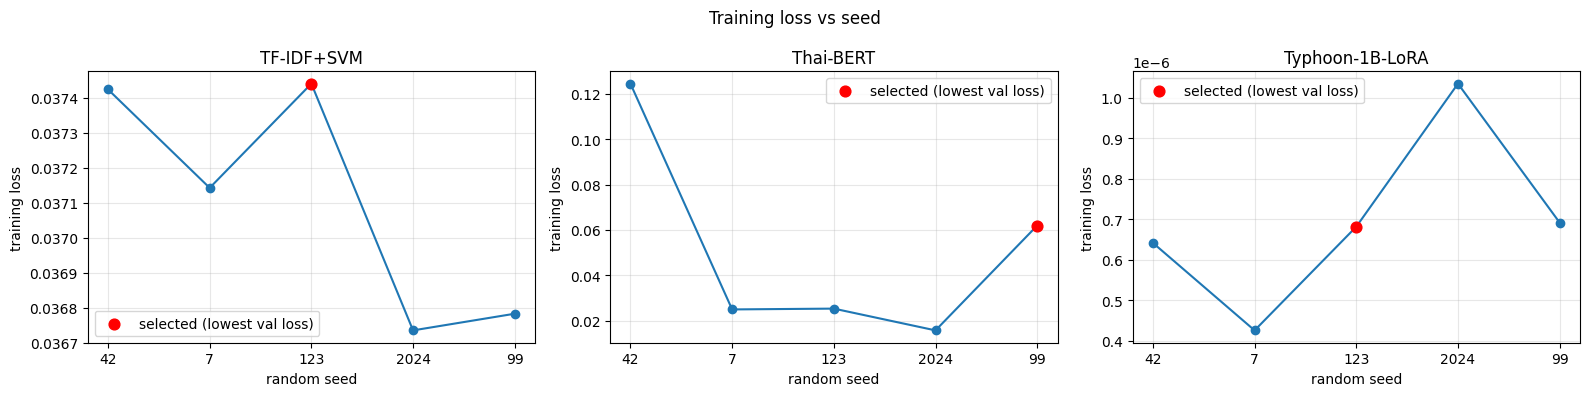

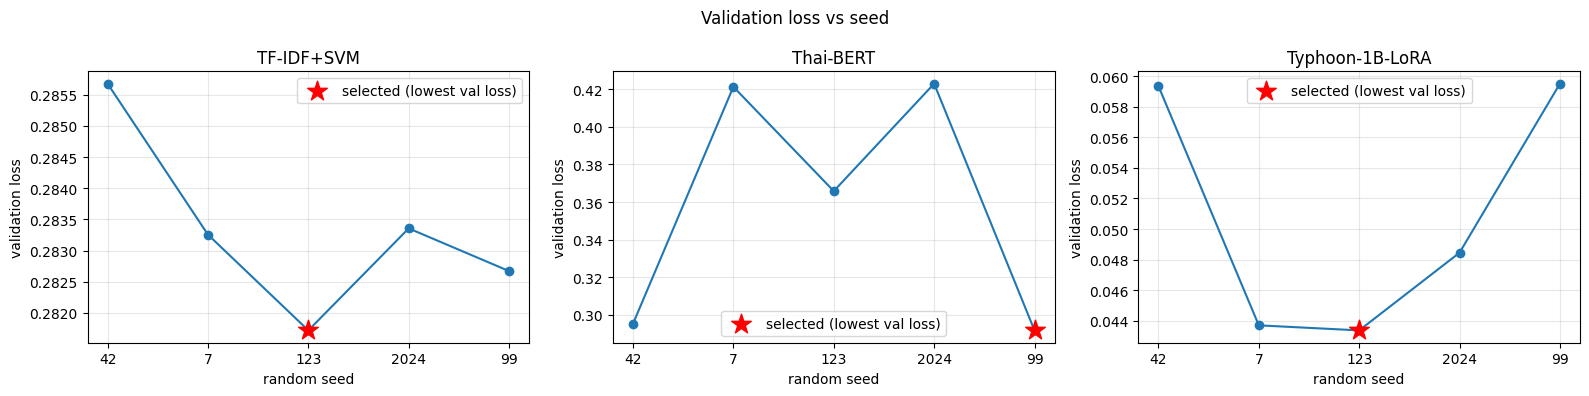

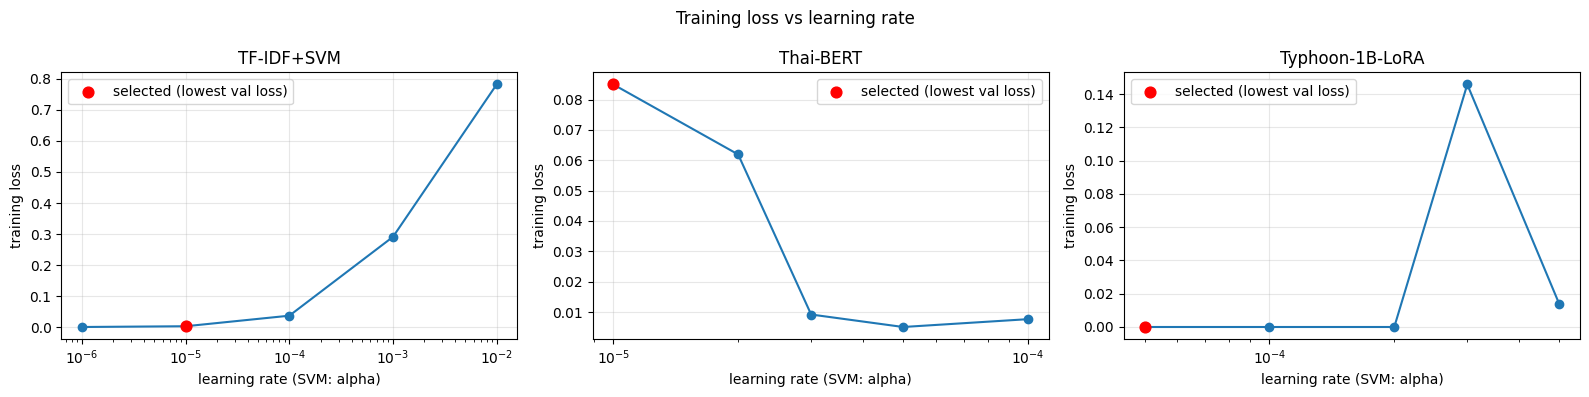

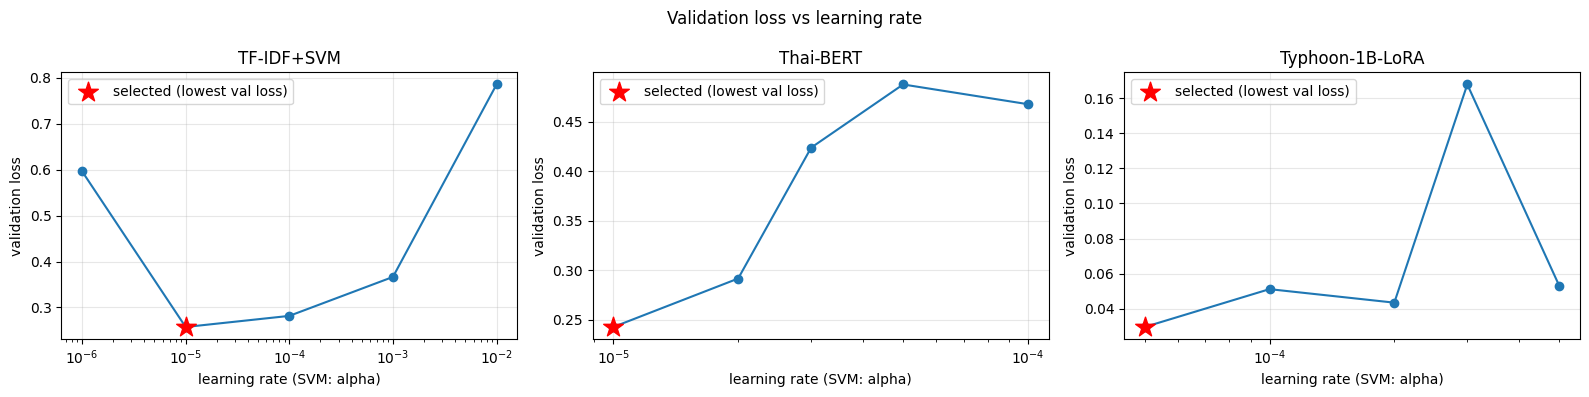

In [16]:
def plot_param(T, xcol, xlabel, col, ylabel, title, fname, logx=False, star=False):
    # 1 รูป = 1 ชนิด loss (train หรือ val) แยก subplot ตามโมเดล
    fig, axes = plt.subplots(1, 3, figsize=(16, 4))
    for ax, m in zip(axes, MODELS):
        d = T[T["model"] == m].reset_index(drop=True)
        xs = d[xcol].values if logx else np.arange(len(d))
        ax.plot(xs, d[col], marker="o")
        k = d["val_loss"].idxmin()          # จุดที่เลือก = val loss ต่ำสุดเสมอ
        ax.scatter([xs[k]], [d.loc[k, col]], marker="*" if star else "o", s=220 if star else 60,
                   c="red", zorder=5, label="selected (lowest val loss)")
        if logx: ax.set_xscale("log")
        else: ax.set_xticks(xs); ax.set_xticklabels(d[xcol].astype(str))
        ax.set_title(m); ax.set_xlabel(xlabel); ax.set_ylabel(ylabel); ax.grid(alpha=.3); ax.legend()
    fig.suptitle(title); plt.tight_layout()
    plt.savefig(f"{OUT}/{fname}", dpi=150, bbox_inches="tight"); plt.show()

# พารามิเตอร์ #2: random seed
plot_param(T2, "seed", "random seed", "train_loss", "training loss", "Training loss vs seed", "fig_train_loss_vs_seed.png")
plot_param(T2, "seed", "random seed", "val_loss", "validation loss", "Validation loss vs seed", "fig_val_loss_vs_seed.png", star=True)
# พารามิเตอร์ #3: learning rate
plot_param(T3, "lr", "learning rate (SVM: alpha)", "train_loss", "training loss", "Training loss vs learning rate", "fig_train_loss_vs_lr.png", logx=True)
plot_param(T3, "lr", "learning rate (SVM: alpha)", "val_loss", "validation loss", "Validation loss vs learning rate", "fig_val_loss_vs_lr.png", logx=True, star=True)

## 8) Unknown test set — รันโมเดลที่ใช้ #1, #2, #3 ที่ดีที่สุดของแต่ละโมเดลบน **test set** (ดูครั้งเดียว ห้ามเอามาปรับค่าต่อ)

In [17]:
FINAL = []
for m in MODELS:
    r = cached(f"{OUT}/final_{m}.pkl",
               lambda m=m: _run(m, BEST_EPOCH[m], BEST_SEED[m], BEST_LR[m], test=True))
    FINAL.append({"model": m, "#1 epochs": BEST_EPOCH[m], "#2 seed": BEST_SEED[m], "#3 lr": BEST_LR[m],
                  "val_F1": r["hist"].iloc[-1]["F1"],
                  "test_P": r["test"]["P"], "test_R": r["test"]["R"], "test_F1": r["test"]["F1"]})
T_FINAL = pd.DataFrame(FINAL)
display(T_FINAL.round(4))
T_FINAL.round(4).to_csv(f"{OUT}/table_final_test.csv", index=False)

Loading weights:   0%|          | 0/197 [00:00<?, ?it/s]

[transformers] CamembertForSequenceClassification LOAD REPORT from: airesearch/wangchanberta-base-att-spm-uncased
Key                         | Status     | 
----------------------------+------------+-
lm_head.layer_norm.bias     | UNEXPECTED | 
lm_head.layer_norm.weight   | UNEXPECTED | 
roberta.pooler.dense.bias   | UNEXPECTED | 
roberta.pooler.dense.weight | UNEXPECTED | 
lm_head.dense.bias          | UNEXPECTED | 
lm_head.bias                | UNEXPECTED | 
lm_head.dense.weight        | UNEXPECTED | 
classifier.dense.weight     | MISSING    | 
classifier.out_proj.weight  | MISSING    | 
classifier.out_proj.bias    | MISSING    | 
classifier.dense.bias       | MISSING    | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.
- MISSING:	those params were newly initialized because missing from the checkpoint. Consider training on your downstream task.


Epoch,Training Loss,Validation Loss,P,R,F1
1,0.593268,0.383547,0.813333,0.884058,0.847222
2,0.386797,0.286059,0.898496,0.865942,0.881919
3,0.290559,0.241781,0.881533,0.916667,0.898757
4,0.239124,0.232494,0.898551,0.898551,0.898551
5,0.191912,0.221717,0.890459,0.913043,0.901610
6,0.150624,0.229405,0.921933,0.898551,0.910092
7,0.135572,0.219255,0.907143,0.920290,0.913669
8,0.109111,0.232368,0.919414,0.909420,0.914390
9,0.092217,0.242626,0.922509,0.905797,0.914077
10,0.084997,0.242884,0.909747,0.913043,0.911392


Training Loss,Validation Loss,Epoch,P,R,F1
0.084997,0.309034,10,0.880435,0.883636,0.882033


Loading weights:   0%|          | 0/146 [00:00<?, ?it/s]

[transformers] LlamaForSequenceClassification LOAD REPORT from: scb10x/llama3.2-typhoon2-1b-instruct
Key          | Status  | 
-------------+---------+-
score.weight | MISSING | 

Notes:
- MISSING:	those params were newly initialized because missing from the checkpoint. Consider training on your downstream task.


Epoch,Training Loss,Validation Loss,P,R,F1
1,0.207405,0.031863,0.996390,1.000000,0.998192
2,0.017924,0.031440,0.996377,0.996377,0.996377
3,0.004386,0.036406,0.996364,0.992754,0.994555
4,0.002656,0.030614,0.996390,1.000000,0.998192
5,0.001536,0.029675,0.996390,1.000000,0.998192
6,0.000298,0.030912,0.996364,0.992754,0.994555
7,0.000045,0.030339,0.996364,0.992754,0.994555
8,0.000002,0.029639,0.996377,0.996377,0.996377
9,0.000002,0.029552,0.996377,0.996377,0.996377
10,0.000001,0.029474,0.996377,0.996377,0.996377


Training Loss,Validation Loss,Epoch,P,R,F1
0.000001,0.046584,10,0.989170,0.996364,0.992754


,model,#1 epochs,#2 seed,#3 lr,val_F1,test_P,test_R,test_F1
0,TF-IDF+SVM,10,123,0.0,0.9031,0.8705,0.8800,0.8752
1,Thai-BERT,10,99,0.0,0.9114,0.8804,0.8836,0.8820
2,Typhoon-1B-LoRA,10,123,0.0,0.9964,0.9892,0.9964,0.9928


In [19]:
import re, glob
from scipy.sparse import vstack

EXT_DIR = "/content/ext"; os.makedirs(EXT_DIR, exist_ok=True)
DROP_NEAR_DUP = False      # True = ตัดข่าวที่เกือบซ้ำกับ train/val (cosine similarity >= NEAR_DUP_TH) ออกจากชุดทดสอบ
NEAR_DUP_TH = 0.9

found = {os.path.basename(p): p for p in glob.glob("/content/*AFNC*.csv") + glob.glob(f"{EXT_DIR}/*AFNC*.csv")}
assert found, "ไม่พบไฟล์ AFNC*.csv ใน /content หรือ /content/ext — อัปโหลดไฟล์ก่อน"

def load_afnc(path):
    # หาปีจากชื่อไฟล์ (รองรับทั้ง ..._2025_fake_news_.csv และ ...(2025 fake news).csv) โดยไม่ไปจับตัวเลข timestamp
    m = re.search(r"(?<!\d)(2025|2026)(?!\d)", os.path.basename(path))
    assert m, f"หาปี 2025/2026 ในชื่อไฟล์ไม่เจอ: {path}"
    d = pd.read_csv(path, encoding="utf-8-sig")
    d = d.loc[:, ~d.columns.str.startswith("Unnamed")]
    # บางไฟล์มีข้อมูลหลายชุดเคียงกัน (คอลัมน์ซ้ำ .1, .2) -> เลือกชุดที่มีหัวข้อข่าวมากที่สุด
    sfx = max(["", ".1", ".2"], key=lambda s: d[f"หัวข้อข่าว{s}"].notna().sum() if f"หัวข้อข่าว{s}" in d else -1)
    out = pd.DataFrame({"Title": d[f"หัวข้อข่าว{sfx}"], "type": d[f"ประเภทข่าว{sfx}"]}).dropna(subset=["Title"])
    out["Title"] = out["Title"].astype(str).str.strip()
    out["label"] = (out["type"].astype(str).str.strip() == "ข่าวปลอม").astype(int)   # ใช้คอลัมน์ "ประเภทข่าว" เป็น label
    out["year"] = int(m.group(1)); out["src"] = os.path.basename(path)
    print(f"{os.path.basename(path)[-28:]:28s} ใช้ชุดคอลัมน์ '{sfx or '(แรก)'}' | {len(out)} แถว | {out['type'].value_counts().to_dict()}")
    return out

EXT = pd.concat([load_afnc(p) for p in sorted(found.values())], ignore_index=True)

# 1) ชื่อข่าวซ้ำ / ซ้ำแต่คนละ label (ตัดทิ้ง)
n0 = len(EXT)
conf = EXT.groupby("Title")["label"].nunique(); EXT = EXT[~EXT["Title"].isin(conf[conf > 1].index)]
EXT = EXT.drop_duplicates(subset="Title").reset_index(drop=True)
print(f"ตัดชื่อข่าวซ้ำ/ขัดแย้งกันเอง: {n0} -> {len(EXT)}")

# 2) ซ้ำกับ dataset เดิมที่ใช้เทรน (train+val+test เดิม) -> ตัดออก ไม่งั้นเป็น data leakage
pool = set(df["Title"].str.strip())
ov = EXT["Title"].isin(pool)
print(f"ซ้ำกับ dataset เดิมแบบตรงตัว: {ov.sum()} แถว -> ตัดออก"); EXT = EXT[~ov].reset_index(drop=True)

# 3) เกือบซ้ำกับ train/val (TF-IDF cosine)
sim = (tfidf.transform(EXT["Title"]) @ vstack([Xtr, Xva]).T).max(axis=1).toarray().ravel()
print(f"เกือบซ้ำกับ train/val: sim>={NEAR_DUP_TH} = {(sim >= NEAR_DUP_TH).sum()} แถว ({(sim >= NEAR_DUP_TH).mean():.1%})")
if DROP_NEAR_DUP:
    EXT = EXT[sim < NEAR_DUP_TH].reset_index(drop=True)

EXT_SETS = {"AFNC 2025": EXT[EXT.year == 2025].reset_index(drop=True),
            "AFNC 2026": EXT[EXT.year == 2026].reset_index(drop=True),
            "AFNC 2025+2026": EXT}
ALL = "AFNC 2025+2026"
comp = EXT.groupby(["year", "label"]).size().unstack().rename(columns={0: "ข่าวจริง", 1: "ข่าวปลอม"})
display(comp)
comp.to_csv(f"{OUT}/external_dataset_composition.csv")

30221100(2025 fake news).csv ใช้ชุดคอลัมน์ '(แรก)' | 500 แถว | {'ข่าวปลอม': 500}
0260930221100(2025_true).csv ใช้ชุดคอลัมน์ '.1' | 500 แถว | {'ข่าวจริง': 500}
30221100(2026 fake news).csv ใช้ชุดคอลัมน์ '(แรก)' | 500 แถว | {'ข่าวปลอม': 500}
0260930221100(2026_true).csv ใช้ชุดคอลัมน์ '(แรก)' | 500 แถว | {'ข่าวจริง': 500}
ตัดชื่อข่าวซ้ำ/ขัดแย้งกันเอง: 2000 -> 2000
ซ้ำกับ dataset เดิมแบบตรงตัว: 0 แถว -> ตัดออก
เกือบซ้ำกับ train/val: sim>=0.9 = 1 แถว (0.1%)


label,ข่าวจริง,ข่าวปลอม
year,,
2025,500,500
2026,500,500


In [22]:
from sklearn.metrics import confusion_matrix

def ext_metrics(y, pred):
    p, r, f = prf(y, pred)
    tn, fp, fn, tp = confusion_matrix(y, pred, labels=[0, 1]).ravel()
    return dict(P=p, R=r, F1=f, acc=float((y == pred).mean()),
                TN=int(tn), FP=int(fp), FN=int(fn), TP=int(tp), preds=np.asarray(pred))

def _run_svm(epochs, seed, alpha, test=False, extra=None):
    rows, vpreds, clf = [], [], None
    for e in range(1, epochs + 1):
        clf = SGDClassifier(loss="hinge", alpha=alpha, max_iter=e, tol=None, random_state=seed)
        clf.fit(Xtr, ytr)
        d_tr, d_va = clf.decision_function(Xtr), clf.decision_function(Xva)
        pred = (d_va > 0).astype(int)
        p, r, f = prf(yva, pred)
        rows.append(dict(epoch=e,
                         train_loss=hinge_loss(ytr, d_tr, labels=[0, 1]),
                         val_loss=hinge_loss(yva, d_va, labels=[0, 1]),
                         P=p, R=r, F1=f))
        vpreds.append(pred)
    res = dict(hist=pd.DataFrame(rows), val_preds=np.array(vpreds), test=None)
    if test:
        d_te = clf.decision_function(Xte)
        p, r, f = prf(yte, (d_te > 0).astype(int))
        res["test"] = dict(test_loss=hinge_loss(yte, d_te, labels=[0, 1]), P=p, R=r, F1=f)
    if extra:
        res["extra"] = {nm: ext_metrics(d["label"].values, (clf.decision_function(tfidf.transform(d["Title"])) > 0).astype(int))
                        for nm, d in extra.items()}
    return res

def encode_df(tok, d, max_len=64):
    ds = Dataset.from_pandas(d[["Title", "label"]].reset_index(drop=True))
    ds = ds.map(lambda b: tok(b["Title"], truncation=True, max_length=max_len), batched=True)
    return ds.remove_columns(["Title"]).rename_column("label", "labels")

def _run_hf(model, epochs, seed, lr, test=False, extra=None):
    name, cfg = HF_CFG[model]
    seed_all(seed)
    tok, tr_ds, va_ds, te_ds = get_data(name)
    net = AutoModelForSequenceClassification.from_pretrained(name, num_labels=2, dtype=torch.float32)
    net.config.pad_token_id = tok.pad_token_id
    if cfg["lora"]:
        from peft import LoraConfig, get_peft_model
        lcfg = LoraConfig(r=16, lora_alpha=32, lora_dropout=0.05, task_type="SEQ_CLS",
                          target_modules=["q_proj", "k_proj", "v_proj", "o_proj"])
        net = get_peft_model(net, lcfg)

    vpreds = []
    def metrics(ep):
        logits, labels = ep
        pred = np.argmax(logits, axis=-1)
        vpreds.append(pred)
        p, r, f = prf(labels, pred)
        return {"P": p, "R": r, "F1": f}

    steps_per_epoch = -(-len(tr_ds) // cfg["batch_size"])
    args = TrainingArguments(
        output_dir=f"/content/out_{model}", num_train_epochs=epochs,
        per_device_train_batch_size=cfg["batch_size"], per_device_eval_batch_size=64,
        learning_rate=lr, weight_decay=0.01, warmup_steps=int(0.05 * steps_per_epoch * epochs),
        eval_strategy="epoch", logging_strategy="epoch", save_strategy="no",
        fp16=torch.cuda.is_available(), seed=seed, data_seed=seed, report_to="none")
    trainer = Trainer(model=net, args=args, train_dataset=tr_ds, eval_dataset=va_ds,
                      data_collator=DataCollatorWithPadding(tok), compute_metrics=metrics)
    trainer.train()

    log = trainer.state.log_history
    tr_loss = {int(round(l["epoch"])): l["loss"] for l in log if "loss" in l and "eval_loss" not in l}
    rows = []
    for l in log:
        if "eval_loss" in l:
            ep = int(round(l["epoch"]))
            rows.append(dict(epoch=ep, train_loss=tr_loss.get(ep, np.nan), val_loss=l["eval_loss"],
                             P=l["eval_P"], R=l["eval_R"], F1=l["eval_F1"]))
    res = dict(hist=pd.DataFrame(rows), val_preds=np.array(vpreds[:epochs]), test=None)
    if test:
        m = trainer.evaluate(te_ds, metric_key_prefix="test")
        res["test"] = dict(test_loss=m["test_loss"], P=m["test_P"], R=m["test_R"], F1=m["test_F1"])

    if extra:
        res["extra"] = {}
        for nm, d in extra.items():
            out = trainer.predict(encode_df(tok, d))
            res["extra"][nm] = ext_metrics(d["label"].values, np.argmax(out.predictions, axis=-1))

    del net, trainer
    gc.collect(); torch.cuda.empty_cache()
    return res

def _run(model, epochs, seed, lr, test=False, extra=None):
    if model == "TF-IDF+SVM":
        return _run_svm(epochs, seed, lr, test, extra)
    return _run_hf(model, epochs, seed, lr, test, extra)

Loading weights:   0%|          | 0/197 [00:00<?, ?it/s]

[transformers] CamembertForSequenceClassification LOAD REPORT from: airesearch/wangchanberta-base-att-spm-uncased
Key                         | Status     | 
----------------------------+------------+-
lm_head.layer_norm.bias     | UNEXPECTED | 
lm_head.layer_norm.weight   | UNEXPECTED | 
roberta.pooler.dense.bias   | UNEXPECTED | 
roberta.pooler.dense.weight | UNEXPECTED | 
lm_head.dense.bias          | UNEXPECTED | 
lm_head.bias                | UNEXPECTED | 
lm_head.dense.weight        | UNEXPECTED | 
classifier.dense.weight     | MISSING    | 
classifier.out_proj.weight  | MISSING    | 
classifier.out_proj.bias    | MISSING    | 
classifier.dense.bias       | MISSING    | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.
- MISSING:	those params were newly initialized because missing from the checkpoint. Consider training on your downstream task.


Epoch,Training Loss,Validation Loss,P,R,F1
1,0.593268,0.383547,0.813333,0.884058,0.847222
2,0.386797,0.286059,0.898496,0.865942,0.881919
3,0.290559,0.241781,0.881533,0.916667,0.898757
4,0.239124,0.232494,0.898551,0.898551,0.898551
5,0.191912,0.221717,0.890459,0.913043,0.901610
6,0.150624,0.229405,0.921933,0.898551,0.910092
7,0.135572,0.219255,0.907143,0.920290,0.913669
8,0.109111,0.232368,0.919414,0.909420,0.914390
9,0.092217,0.242626,0.922509,0.905797,0.914077
10,0.084997,0.242884,0.909747,0.913043,0.911392


Training Loss,Validation Loss,Epoch,P,R,F1
0.084997,0.309034,10,0.880435,0.883636,0.882033


Map:   0%|          | 0/1000 [00:00<?, ? examples/s]

Map:   0%|          | 0/1000 [00:00<?, ? examples/s]

... (6 outputs left out)

Map:   0%|          | 0/1000 [00:00<?, ? examples/s]

Map:   0%|          | 0/2000 [00:00<?, ? examples/s]

,model,set,n,P,R,F1,acc,TP,FP,FN,TN
0,TF-IDF+SVM,test (in-domain),575,0.8705,0.8800,0.8752,NaN,NaN,NaN,NaN,NaN
1,TF-IDF+SVM,AFNC 2025,1000,0.7654,0.7960,0.7804,0.776,398.0,122.0,102.0,378.0
2,TF-IDF+SVM,AFNC 2026,1000,0.7851,0.6940,0.7367,0.752,347.0,95.0,153.0,405.0
3,TF-IDF+SVM,AFNC 2025+2026,2000,0.7744,0.7450,0.7594,0.764,745.0,217.0,255.0,783.0
4,Thai-BERT,test (in-domain),575,0.8804,0.8836,0.8820,NaN,NaN,NaN,NaN,NaN
5,Thai-BERT,AFNC 2025,1000,0.7925,0.8480,0.8193,0.813,424.0,111.0,76.0,389.0
6,Thai-BERT,AFNC 2026,1000,0.8403,0.7680,0.8025,0.811,384.0,73.0,116.0,427.0
7,Thai-BERT,AFNC 2025+2026,2000,0.8145,0.8080,0.8112,0.812,808.0,184.0,192.0,816.0
8,Typhoon-1B-LoRA,test (in-domain),575,0.9892,0.9964,0.9928,NaN,NaN,NaN,NaN,NaN
9,Typhoon-1B-LoRA,AFNC 2025,1000,0.8434,0.1400,0.2401,0.557,70.0,13.0,430.0,487.0


model,TF-IDF+SVM,Thai-BERT,Typhoon-1B-LoRA
set,,,
test (in-domain),0.8752,0.8820,0.9928
AFNC 2025,0.7804,0.8193,0.2401
AFNC 2026,0.7367,0.8025,0.1770
AFNC 2025+2026,0.7594,0.8112,0.2091


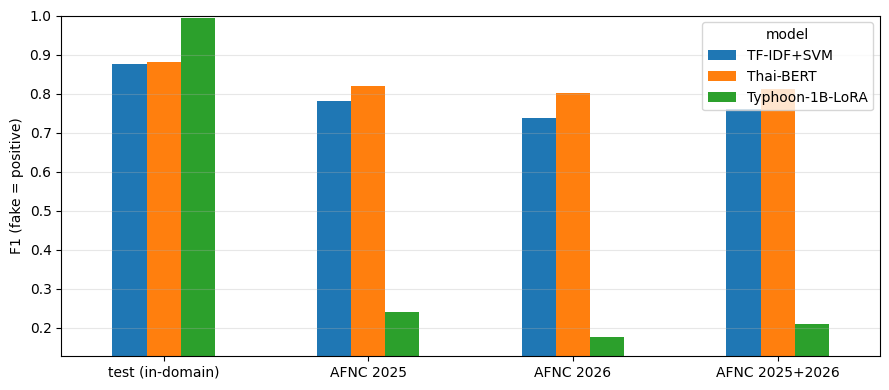

In [23]:
FINAL_EXT = {}
for m in MODELS:
    FINAL_EXT[m] = cached(f"{OUT}/final_ext_{m}_{len(EXT)}.pkl",
                          lambda m=m: _run(m, BEST_EPOCH[m], BEST_SEED[m], BEST_LR[m], test=True, extra=EXT_SETS))

rows = []
for m in MODELS:
    t = FINAL_EXT[m]["test"]
    rows.append(dict(model=m, set="test (in-domain)", n=len(test_df), P=t["P"], R=t["R"], F1=t["F1"]))
    for nm, d in EXT_SETS.items():
        e = FINAL_EXT[m]["extra"][nm]
        rows.append(dict(model=m, set=nm, n=len(d), P=e["P"], R=e["R"], F1=e["F1"], acc=e["acc"],
                         TP=e["TP"], FP=e["FP"], FN=e["FN"], TN=e["TN"]))
T_EXT = pd.DataFrame(rows)
display(T_EXT.round(4))
T_EXT.round(4).to_csv(f"{OUT}/table_external_test.csv", index=False)

ORDER = ["test (in-domain)", "AFNC 2025", "AFNC 2026", "AFNC 2025+2026"]
piv = T_EXT.pivot(index="set", columns="model", values="F1").loc[ORDER, MODELS]
display(piv.round(4))
ax = piv.plot(kind="bar", figsize=(9, 4), rot=0); ax.set_ylabel("F1 (fake = positive)"); ax.set_xlabel("")
ax.set_ylim(max(0, piv.values.min() - 0.05), 1.0); ax.grid(alpha=.3, axis="y")
plt.tight_layout(); plt.savefig(f"{OUT}/fig_external_f1.png", dpi=150, bbox_inches="tight"); plt.show()

In [24]:
PRED = EXT_SETS[ALL][["Title", "label", "year"]].reset_index(drop=True).copy()
for m in MODELS:
    PRED[m] = FINAL_EXT[m]["extra"][ALL]["preds"]
PRED.to_csv(f"{OUT}/external_predictions.csv", index=False, encoding="utf-8-sig")

wrong = PRED[PRED[MODELS].ne(PRED["label"], axis=0).any(axis=1)]
print(f"ข่าวที่มีอย่างน้อย 1 โมเดลทายผิด: {len(wrong)} / {len(PRED)}")
for m in MODELS:
    w = PRED[PRED[m] != PRED["label"]]
    print(f"\n{m}: ผิด {len(w)} ข่าว | แยกตามปี {w['year'].value_counts().to_dict()} | ข่าวปลอมที่หลุด (FN) {int(((w['label']==1)).sum())}, ข่าวจริงที่ถูกทายเป็นปลอม (FP) {int(((w['label']==0)).sum())}")
    display(w[["Title", "label", "year"]].head(10))

ข่าวที่มีอย่างน้อย 1 โมเดลทายผิด: 1187 / 2000

TF-IDF+SVM: ผิด 472 ข่าว | แยกตามปี {2026: 248, 2025: 224} | ข่าวปลอมที่หลุด (FN) 255, ข่าวจริงที่ถูกทายเป็นปลอม (FP) 217


,Title,label,year
0,ธ.ก.ส. เปิดสินเชื่อด่วนเพื่อการเกษตร ลงทะเบียน...,1,2025
2,ธ.ก.ส. ประกาศมอบเงินช่วยเหลือ 1 แสนบาทให้ 4 กล...,1,2025
14,ธ.ออมสิน เปิดโครงการระบบออนไลน์ร่วมกับ 16 ธนาค...,1,2025
20,สำนักงานตรวจคนเข้าเมืองของไทย คุกคามนักท่องเที...,1,2025
24,ผู้สูงอายุ 50 ปีขึ้นไป จะได้รับเงินสดดิจิทัลจา...,1,2025
27,กระสุนคลัสเตอร์ที่ไทยใช้ เป็นกับดักสำหรับพลเรื...,1,2025
35,กัมพูชาเร่งรื้อถอนเขื่อนกันคลื่น 73 หลังจากโดน...,1,2025
36,ธงชาติกัมพูชาโบกสะบัดเหนือ ช่องอานม้า ระหว่าง ...,1,2025
37,ไทยโจมตีโรงเรียนประถมศึกษาในเขตเศรษฐกิจพิเศษทม...,1,2025
38,ไทยใช้ปืนเล็กยาวและระเบิด โจมตีรถสาธารณะของพลเ...,1,2025



Thai-BERT: ผิด 376 ข่าว | แยกตามปี {2026: 189, 2025: 187} | ข่าวปลอมที่หลุด (FN) 192, ข่าวจริงที่ถูกทายเป็นปลอม (FP) 184


,Title,label,year
22,"ธ.ก.ส. เปิดโครงการแก้หนี้นอกระบบ กู้ 50,000 บา...",1,2025
37,ไทยโจมตีโรงเรียนประถมศึกษาในเขตเศรษฐกิจพิเศษทม...,1,2025
46,ท่าอากาศยานไทยเลือกปฏิบัติกับผู้โดยสารที่เดินท...,1,2025
57,สั่งปิดอ่าวไทย สกัดเส้นทางลำเลียงอาวุธที่อาจเช...,1,2025
74,"แอฟริกาสั่งซื้อข้าวไทยเพิ่ม 300,000 ตัน",1,2025
77,การรถไฟฯ จัดขบวนรถพิเศษ ส่งเรือสนับสนุนภารกิจก...,1,2025
98,รัฐบาลเพิ่มเงินอุดหนุนพิเศษให้ผู้สูงอายุ เริ่ม...,1,2025
130,กรมท่าอากาศยาน งดให้บริการเที่ยวบิน ระหว่างไทย...,1,2025
132,เริ่มจำหน่ายสลาก กอช. (หวยเกษียณ) งวดแรก เดือน...,1,2025
135,คณะทูต AOT อนุญาตให้ไทยเปิดศึกกัมพูชาได้,1,2025



Typhoon-1B-LoRA: ผิด 908 ข่าว | แยกตามปี {2026: 465, 2025: 443} | ข่าวปลอมที่หลุด (FN) 880, ข่าวจริงที่ถูกทายเป็นปลอม (FP) 28


,Title,label,year
0,ธ.ก.ส. เปิดสินเชื่อด่วนเพื่อการเกษตร ลงทะเบียน...,1,2025
1,รับทำใบขับขี่ออนไลน์ถูกกฎหมาย ไม่ต้องสอบเองที่...,1,2025
2,ธ.ก.ส. ประกาศมอบเงินช่วยเหลือ 1 แสนบาทให้ 4 กล...,1,2025
3,ปปง. เปิดให้ผู้เสียหายจากแก๊งคอลเซนเตอร์ ลงทะเ...,1,2025
4,ทำใบขับขี่ไม่ใช่เรื่องยาก ผ่านเพจ พงษ์เพชร์ กง...,1,2025
5,กรมการขนส่งทางบก เปิดรับทำใบขับขี่ ผ่าน TikTok...,1,2025
6,เพจ Australian Employment เปิดรับแรงงานชาย-หญิ...,1,2025
7,รับทำใบขับขี่ออนไลน์ถูกกฎหมาย ไม่ต้องสอบเองที่...,1,2025
8,เพจ Asian Job Company เปิดรับสมัครแรงงานไปทำงา...,1,2025
10,ธ.กรุงไทย ใช้บัญชีติ๊กต็อกที่ชื่อ nmlovuhbpl0 ...,1,2025


In [25]:
for nm, X in [("test (in-domain)", Xte), ("AFNC 2025+2026", tfidf.transform(EXT["Title"]))]:
    sim = (X @ Xtr.T).max(axis=1).toarray().ravel()
    print(nm, "| median sim =", round(float(np.median(sim)), 3),
          "| sim>=0.8:", f"{(sim >= 0.8).mean():.1%}", "| sim>=0.9:", f"{(sim >= 0.9).mean():.1%}")

test (in-domain) | median sim = 0.36 | sim>=0.8: 7.3% | sim>=0.9: 4.3%
AFNC 2025+2026 | median sim = 0.306 | sim>=0.8: 0.2% | sim>=0.9: 0.1%


In [26]:
def style(d, name):
    t = d["Title"]
    out = pd.DataFrame({"len": t.str.len(), "has_digit": t.str.contains(r"\d"),
                        "has_quote": t.str.contains("\"|'|“|”"), "has_excl": t.str.contains("!"),
                        "label": d["label"]})
    print(f"== {name}"); display(out.groupby("label").mean().rename(index={0: "จริง", 1: "ปลอม"}).round(3))

style(df, "dataset เดิม (train+val+test)")
style(EXT, "AFNC 2025+2026")

svm_ = SGDClassifier(loss="hinge", alpha=DEFAULT_LR["TF-IDF+SVM"], max_iter=MAX_EPOCH, tol=None, random_state=SEED).fit(Xtr, ytr)
vocab, w = np.array(tfidf.get_feature_names_out()), svm_.coef_[0]
print("คำชี้ไปทางข่าวปลอม:", vocab[np.argsort(-w)[:20]].tolist())
print("คำชี้ไปทางข่าวจริง:", vocab[np.argsort(w)[:20]].tolist())

== dataset เดิม (train+val+test)


,len,has_digit,has_quote,has_excl
label,,,,
จริง,85.793,0.613,0.103,0.024
ปลอม,66.295,0.421,0.009,0.025


== AFNC 2025+2026


,len,has_digit,has_quote,has_excl
label,,,,
จริง,67.144,0.482,0.031,0.006
ปลอม,67.614,0.378,0.015,0.002


คำชี้ไปทางข่าวปลอม: ['เพจ', 'ผลิตภัณฑ์', 'รับสมัคร', 'ทำให้', 'หุ้น', 'บาท', 'พายุ', 'ไลน์', 'ตลาดหลักทรัพย์', 'จะ', 'กรุงไทย', 'เงิน', 'ลงทุน', 'อุณหภูมิ', 'ประเทศ ไทย', 'เสี่ยง โควิด', 'ตลาดหลักทรัพย์ ฯ', 'เรียก', 'นาที', 'ข่าว ปลอม']
คำชี้ไปทางข่าวจริง: ['?', 'ครม.', 'กรณี', 'ฟรี', 'เตือน มะเร็ง', 'อนุมัติ', 'อัตรา', 'ผู้ประกันตน', 'ปรับ', 'สปสช.', 'และ อาจ', '"', 'เดินหน้า', 'ร้อนใน', 'เผย', 'เหตุ', '67', 'ธอส.', 'ตรวจ', 'กทม.']


In [27]:
from google.colab import drive
drive.mount('/content/drive')
!cp -r results /content/drive/MyDrive/fake_news_results

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
